In [1]:
from pathlib import Path

# Path of the raw data folder from the project root
RAW_DIR = Path("../data/raw/UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language")

print("Path exists:", RAW_DIR.exists())
print("Number of items inside:", len(list(RAW_DIR.iterdir())))

Path exists: True
Number of items inside: 36


In [2]:
import pandas as pd

def count_images(folder):
    # check the extension of each file in lowercase,
    # so that .jpg / .JPG are not counted twice
    return sum(1 for f in folder.iterdir() if f.is_file() and f.suffix.lower() == ".jpg")

counts = []
for folder in sorted(RAW_DIR.iterdir()):
    if folder.is_dir():
        counts.append({"folder": folder.name, "num_images": count_images(folder)})

df_counts = pd.DataFrame(counts)
print("Total classes:", len(df_counts))
print("Total images:", df_counts["num_images"].sum())
df_counts

Total classes: 36
Total images: 2896


,folder,num_images
0,1-Hay-Original,81
1,Ain-Original,79
2,Alif-Original,81
3,Bay-Original,82
4,Byeh-Original,80
5,Chay-Original,81
6,Cyeh-Original,80
7,Daal-Original,81
8,Dal-Original,78
9,Dochahay-Original,80


In [3]:
expected = 2897
actual = df_counts["num_images"].sum()
diff = expected - actual

print("According to the paper:", expected)
print("We found:", actual)
print("Difference:", diff)

According to the paper: 2897
We found: 2896
Difference: 1


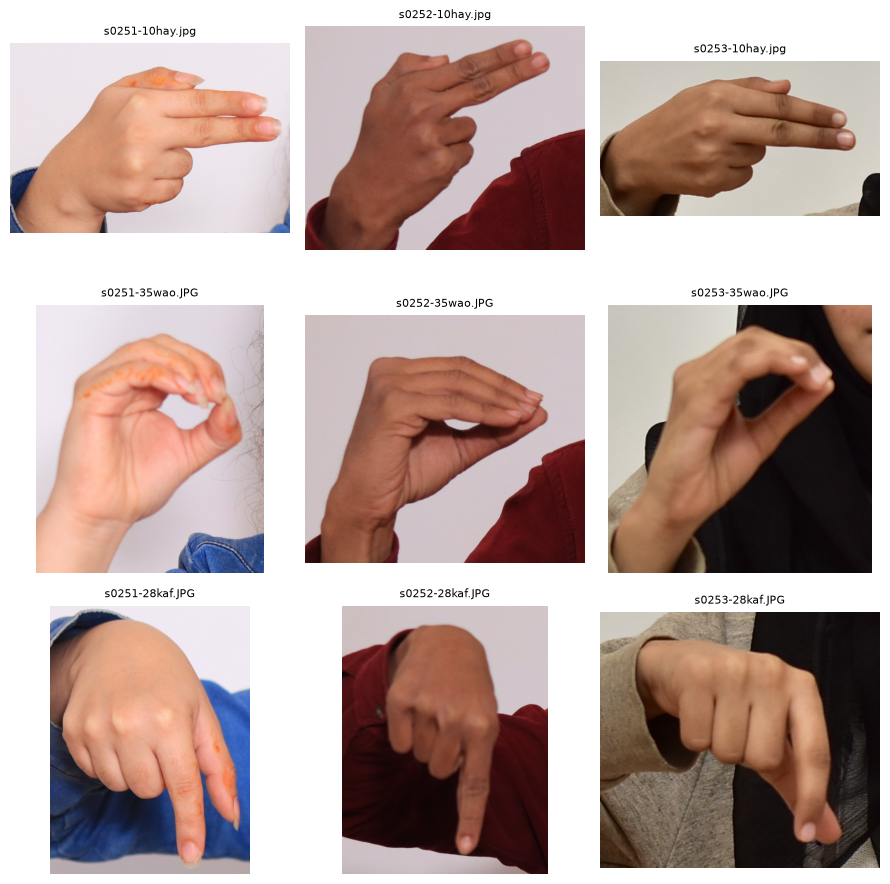

In [4]:
import matplotlib.pyplot as plt
import cv2

# look at 3 images from each of 3 different letters
sample_folders = ["1-Hay-Original", "Wao-Original", "Kaf-Original"]

fig, axes = plt.subplots(len(sample_folders), 3, figsize=(9, 9))

for row, folder_name in enumerate(sample_folders):
    folder = RAW_DIR / folder_name
    images = sorted([f for f in folder.iterdir() if f.suffix.lower() == ".jpg"])[:3]
    for col, img_path in enumerate(images):
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # OpenCV reads BGR, matplotlib wants RGB
        axes[row, col].imshow(img_rgb)
        axes[row, col].set_title(img_path.name, fontsize=8)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [5]:
import re

def get_signer_id(filename):
    # get "s0251" from a filename like "s0251-10hay.jpg"
    match = re.match(r"(s\d+)", filename)
    return match.group(1) if match else None

duplicate_report = []
for folder in sorted(RAW_DIR.iterdir()):
    if folder.is_dir():
        files = [f.name for f in folder.iterdir() if f.suffix.lower() == ".jpg"]
        signer_ids = [get_signer_id(f) for f in files]
        # count how many times each signer ID appeared
        counts = pd.Series(signer_ids).value_counts()
        repeated = counts[counts > 1]
        if len(repeated) > 0:
            duplicate_report.append({"folder": folder.name, "repeated_signers": dict(repeated)})

print("Folders with a duplicate signer:", len(duplicate_report))
for item in duplicate_report:
    print(item)

Folders with a duplicate signer: 0


In [6]:
import sys
sys.path.append("..")  # so that we can import the src/ folder

from src.landmarks import extract_landmarks

# test one image from each of 5 different letters
test_files = [
    RAW_DIR / "1-Hay-Original" / "s0251-10hay.jpg",
    RAW_DIR / "Wao-Original" / "s0251-35wao.JPG",
    RAW_DIR / "Kaf-Original" / "s0251-28kaf.JPG",
    RAW_DIR / "Alif-Original" / list((RAW_DIR / "Alif-Original").glob("s0251*"))[0].name,
    RAW_DIR / "Bay-Original" / list((RAW_DIR / "Bay-Original").glob("s0251*"))[0].name,
]

for f in test_files:
    result = extract_landmarks(f)
    if result is None:
        print(f"{f.name}: NO HAND FOUND")
    else:
        print(f"{f.name}: {len(result)} numbers found, first 3 -> {result[:3]}")

s0251-10hay.jpg: 63 numbers found, first 3 -> [0.20540645718574524, 0.7189399003982544, 1.2131567928008735e-06]
s0251-35wao.JPG: 63 numbers found, first 3 -> [0.30758044123649597, 0.7426687479019165, 1.5479910189242219e-06]
s0251-28kaf.JPG: 63 numbers found, first 3 -> [0.31923916935920715, 0.0969964861869812, -7.483529884666495e-07]
s0251-02alif.jpg: 63 numbers found, first 3 -> [0.4748762249946594, 0.546532392501831, -5.232724333836813e-07]
s0251-03bay.jpg: 63 numbers found, first 3 -> [0.6077092289924622, 0.9411786794662476, 9.332821377938672e-07]


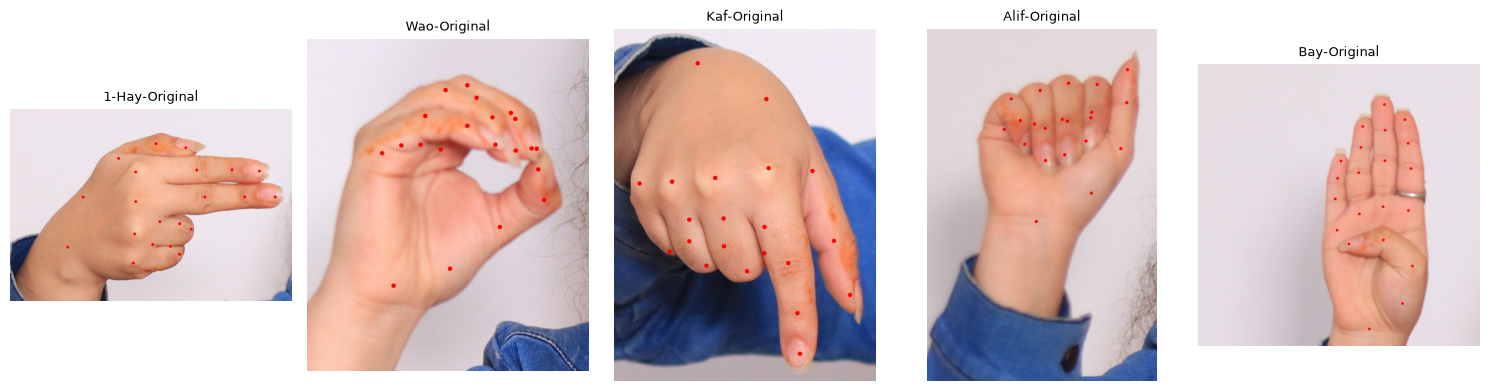

In [7]:
import cv2
import matplotlib.pyplot as plt

def draw_landmarks_on_image(image_path, landmarks):
    img = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # landmarks are between 0 and 1 (normalized); convert them to the real pixels of the image
    for i in range(0, len(landmarks), 3):
        x = int(landmarks[i] * w)
        y = int(landmarks[i + 1] * h)
        cv2.circle(img_rgb, (x, y), 6, (255, 0, 0), -1)  # red dot

    return img_rgb


fig, axes = plt.subplots(1, len(test_files), figsize=(15, 4))

for ax, f in zip(axes, test_files):
    result = extract_landmarks(f)
    if result is not None:
        img_with_dots = draw_landmarks_on_image(f, result)
        ax.imshow(img_with_dots)
        ax.set_title(f.parent.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import sys
sys.path.append("..")
from src.features import normalize_landmarks
import numpy as np

# take the landmarks of one real image
original = extract_landmarks(test_files[0])

# make a "fake small hand": halve all the numbers
# (a hand far from the camera looks smaller)
smaller_hand = [v * 0.5 for v in original]

norm_original = normalize_landmarks(original)
norm_smaller = normalize_landmarks(smaller_hand)

print("Original (first 6 numbers):", np.round(norm_original[:6], 4))
print("Smaller hand (first 6 numbers):", np.round(norm_smaller[:6], 4))

# the difference between the two should be very small (near zero)
diff = np.abs(norm_original - norm_smaller).max()
print("\nLargest difference:", diff)
print("Test pass?", diff < 0.01)

Original (first 6 numbers): [ 0.      0.      0.      0.1441 -0.6962 -0.0467]
Smaller hand (first 6 numbers): [ 0.      0.      0.      0.1441 -0.6962 -0.0467]

Largest difference: 0.0
Test pass? True
